<a href="https://colab.research.google.com/github/natalie400/SemProject_MLEngine/blob/main/Model_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mount Google Drive so Colab can read the uploaded dataset and save training outputs
from google.colab import drive
import os

drive.mount('/content/drive')

# Path to the compressed dataset archive in Google Drive
# (Adjust the path if you placed it inside a subfolder rather than MyDrive root)
archive_path = '/content/drive/MyDrive/RDD2022_YOLO.tar.gz'
extract_dir = '/content/RDD2022_YOLO'

if os.path.exists(archive_path):
    if not os.path.exists(extract_dir):
        print("Extracting RDD2022_YOLO.tar.gz to /content/ ...")
        !tar -xzf "{archive_path}" -C /content/
        print("Extraction complete!")
    else:
        print("Dataset directory already exists at /content/RDD2022_YOLO")
else:
    print(f"ERROR: Archive not found at {archive_path}. Check your Google Drive path.")

Mounted at /content/drive
Extracting RDD2022_YOLO.tar.gz to /content/ ...
Extraction complete!


In [ ]:
import random, shutil
from pathlib import Path
from collections import Counter, defaultdict

def read_split(src, split):
    """[(image_path, [label lines])] for one split, only images that have at least one box."""
    items = []
    for img in sorted((src / 'images' / split).iterdir()):
        if img.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
            continue
        lbl = src / 'labels' / split / f'{img.stem}.txt'
        if not lbl.exists():
            continue
        lines = [ln.strip() for ln in lbl.read_text().splitlines() if ln.strip()]
        if lines:
            items.append((img, lines))
    return items

def classes_in(lines):
    return {int(float(ln.split()[0])) for ln in lines}

def build_subset(src, dst, images_per_class=350, val_images=1000, seed=42):
    src, dst = Path(src), Path(dst)
    rng = random.Random(seed)
    train_items = read_split(src, 'train')   # train split ONLY: the original val split stays untouched
    val_items = read_split(src, 'val')

    cls_of = [classes_in(lines) for _, lines in train_items]
    by_class = defaultdict(list)
    for idx, cs in enumerate(cls_of):
        for c in cs:
            by_class[c].append(idx)

    selected = set()
    for c in sorted(by_class, key=lambda k: len(by_class[k])):          # rarest class first
        have = sum(1 for i in selected if c in cls_of[i])
        pool = [i for i in by_class[c] if i not in selected]
        rng.shuffle(pool)
        selected.update(pool[:max(0, images_per_class - have)])

    train_sel = [train_items[i] for i in sorted(selected)]              # whole images, all labels kept
    val_sel = rng.sample(val_items, min(val_images, len(val_items)))

    if dst.exists():
        shutil.rmtree(dst)
    for split, items in (('train', train_sel), ('val', val_sel)):
        (dst / 'images' / split).mkdir(parents=True)
        (dst / 'labels' / split).mkdir(parents=True)
        for img, lines in items:
            shutil.copy2(img, dst / 'images' / split / img.name)
            (dst / 'labels' / split / f'{img.stem}.txt').write_text('\n'.join(lines) + '\n')

    names = ['D00', 'D01', 'D10', 'D11', 'D20', 'D40', 'D43', 'D44', 'D50']
    yaml = f"path: {dst}\ntrain: images/train\nval: images/val\n\nnames:\n" + \
           ''.join(f"  {i}: {n}\n" for i, n in enumerate(names))
    (dst / 'dataset.yaml').write_text(yaml)

    for split, items in (('train', train_sel), ('val', val_sel)):
        counts = Counter(int(float(l.split()[0])) for _, lines in items for l in lines)
        print(f"\n{split}: {len(items)} images")
        for i, n in enumerate(names):
            print(f"  {n}: {counts.get(i, 0)} boxes")
    return train_sel, val_sel

build_subset('/content/RDD2022_YOLO', '/content/RDD2022_Subset',
             images_per_class=350, val_images=1000)


train: 1375 images
  D00: 619 boxes
  D01: 147 boxes
  D10: 551 boxes
  D11: 36 boxes
  D20: 499 boxes
  D40: 635 boxes
  D43: 383 boxes
  D44: 460 boxes
  D50: 562 boxes

val: 1000 images
  D00: 1015 boxes
  D01: 9 boxes
  D10: 413 boxes
  D11: 2 boxes
  D20: 381 boxes
  D40: 225 boxes
  D43: 21 boxes
  D44: 188 boxes
  D50: 174 boxes


([(PosixPath('/content/RDD2022_YOLO/images/train/China_Drone_000102.jpg'),
   ['2 0.180664 0.542969 0.251953 0.046875']),
  (PosixPath('/content/RDD2022_YOLO/images/train/China_Drone_000179.jpg'),
   ['2 0.248047 0.737305 0.261719 0.052734',
    '0 0.143555 0.625977 0.037109 0.154297']),
  (PosixPath('/content/RDD2022_YOLO/images/train/China_Drone_000205.jpg'),
   ['0 0.328125 0.575195 0.378906 0.427734',
    '5 0.305664 0.189453 0.087891 0.109375',
    '4 0.110352 0.075195 0.216797 0.146484',
    '0 0.524414 0.138672 0.251953 0.195312']),
  (PosixPath('/content/RDD2022_YOLO/images/train/China_Drone_000374.jpg'),
   ['2 0.377930 0.201172 0.361328 0.058594']),
  (PosixPath('/content/RDD2022_YOLO/images/train/China_Drone_000429.jpg'),
   ['2 0.698242 0.652344 0.337891 0.054688',
    '0 0.569336 0.444336 0.044922 0.232422']),
  (PosixPath('/content/RDD2022_YOLO/images/train/China_Drone_000563.jpg'),
   ['2 0.793945 0.209961 0.345703 0.060547']),
  (PosixPath('/content/RDD2022_YOLO/images/

In [ ]:
!pip install -q ultralytics
import torch, ultralytics
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
CUDA available: False


=== Split Summary ===
Train -> Images: 20912, Labels: 20912
Val   -> Images: 5228, Labels: 5228
Total -> Images: 26140, Labels: 26140

Total Bounding Boxes: 64662
Average Damage Instances per Annotated Image: 2.47

             Damage Class  Instance Count
D11: Trans. Lateral Crack              45
 D01: Long. Lateral Crack             179
      D43: Crosswalk Blur             793
        D50: Other Damage            3581
     D44: White Line Blur            5057
             D40: Pothole            6544
     D20: Alligator Crack           10617
    D10: Transverse Crack           11830
  D00: Longitudinal Crack           26016


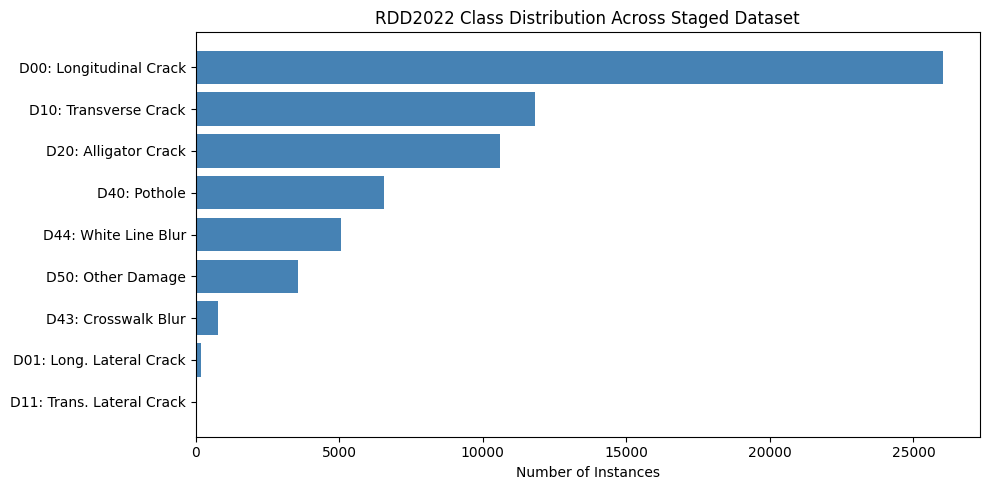

In [ ]:
# Compute dataset split counts, class distribution, and average defects per image
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

dataset_dir = Path('/content/RDD2022_YOLO')

class_names = {
    0: 'D00: Longitudinal Crack',
    1: 'D01: Long. Lateral Crack',
    2: 'D10: Transverse Crack',
    3: 'D11: Trans. Lateral Crack',
    4: 'D20: Alligator Crack',
    5: 'D40: Pothole',
    6: 'D43: Crosswalk Blur',
    7: 'D44: White Line Blur',
    8: 'D50: Other Damage'
}

# Check train and val image/label counts
train_imgs = len(list((dataset_dir / 'images' / 'train').glob('*.jpg')))
val_imgs = len(list((dataset_dir / 'images' / 'val').glob('*.jpg')))
train_lbls = len(list((dataset_dir / 'labels' / 'train').glob('*.txt')))
val_lbls = len(list((dataset_dir / 'labels' / 'val').glob('*.txt')))

print("=== Split Summary ===")
print(f"Train -> Images: {train_imgs}, Labels: {train_lbls}")
print(f"Val   -> Images: {val_imgs}, Labels: {val_lbls}")
print(f"Total -> Images: {train_imgs + val_imgs}, Labels: {train_lbls + val_lbls}\n")

# Count class instances and bounding boxes per image
label_files = list(dataset_dir.rglob('labels/**/*.txt'))
class_counts = Counter()
boxes_per_image = []

for txt_file in label_files:
    lines = [ln.strip() for ln in txt_file.read_text().splitlines() if ln.strip()]
    boxes_per_image.append(len(lines))
    for line in lines:
        class_id = int(line.split()[0])
        class_counts[class_names.get(class_id, f'Unknown ({class_id})')] += 1

avg_boxes = sum(boxes_per_image) / len(boxes_per_image) if boxes_per_image else 0
print(f"Total Bounding Boxes: {sum(boxes_per_image)}")
print(f"Average Damage Instances per Annotated Image: {avg_boxes:.2f}\n")

df_eda = pd.DataFrame(
    class_counts.items(),
    columns=['Damage Class', 'Instance Count']
).sort_values(by='Instance Count', ascending=True)

print(df_eda.to_string(index=False))

# Plot horizontal bar chart of class distribution
plt.figure(figsize=(10, 5))
plt.barh(df_eda['Damage Class'], df_eda['Instance Count'], color='steelblue')
plt.xlabel('Number of Instances')
plt.title('RDD2022 Class Distribution Across Staged Dataset')
plt.tight_layout()
plt.show()

In [ ]:
# Install Ultralytics YOLOv8 package and verify GPU availability
!pip install -q ultralytics

import torch
import ultralytics

print(f"Ultralytics version: {ultralytics.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU device: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: No GPU detected. Go to Runtime -> Change runtime type -> Select T4 GPU.")

Ultralytics version: 8.4.218
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU device: Tesla T4


In [ ]:
# Ensure dataset.yaml points to /content/RDD2022_YOLO inside Colab
import yaml
from pathlib import Path

yaml_path = Path('/content/RDD2022_YOLO/dataset.yaml')

with open(yaml_path, 'r') as f:
    config = yaml.safe_load(f)

config['path'] = '/content/RDD2022_YOLO'
config['train'] = 'images/train'
config['val'] = 'images/val'

with open(yaml_path, 'w') as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Updated dataset.yaml:")
print(yaml_path.read_text())

Updated dataset.yaml:
path: /content/RDD2022_YOLO
train: images/train
val: images/val
names:
  0: D00
  1: D01
  2: D10
  3: D11
  4: D20
  5: D40
  6: D43
  7: D44
  8: D50



In [ ]:
import gc, torch
from ultralytics import YOLO

gc.collect(); torch.cuda.empty_cache()

COMMON = dict(
    data='/content/RDD2022_Subset/dataset.yaml',
    epochs=20, imgsz=640, batch=16, workers=2, cache=False,
    project='/content/runs', exist_ok=True,    # local disk: fast and safer than writing to Drive
    patience=8, plots=False,
)

YOLO('yolov8n.pt').train(name='v8n_subset', **COMMON)
gc.collect(); torch.cuda.empty_cache()
YOLO('yolov5nu.pt').train(name='v5nu_subset', **COMMON)

!cp -r /content/runs /content/drive/MyDrive/RDD2022_Comparisons_v2   # backup to Drive

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/RDD2022_Subset/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8n_subset, nbs=64, nms=None, opset=None, optimize=Fa

In [ ]:
from ultralytics import YOLO
import pandas as pd

DATA = '/content/RDD2022_Subset/dataset.yaml'
models = {
    'YOLOv8n - balanced subset, 20 epochs': '/content/runs/v8n_subset/weights/best.pt',
    'YOLOv5nu - balanced subset, 20 epochs': '/content/runs/v5nu_subset/weights/best.pt',
}
rows = []
for name, weights in models.items():
    m = YOLO(weights).val(data=DATA, imgsz=640, batch=16, plots=False, verbose=False)
    rows.append({
        'Model': name,
        'Precision': m.box.mp,
        'Recall': m.box.mr,
        'mAP50': m.box.map50,
        'mAP50-95': m.box.map,
        'ms/img': m.speed['inference']
    })
results = pd.DataFrame(rows).round(3)
display(results)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/RDD2022_Runs/RDD2022_YOLOv8n_Baseline/weights/best.pt'

## Deliverable 3: Modelling Approach & Validation Measures

### Base Model & Training Configuration
* **Base Model:** Pre-trained `yolov8n.pt` (YOLOv8 Nano) from Ultralytics, chosen for fast training and lightweight inference.
* **Input Resolution (`imgsz`):** `640x640` pixels.
* **Batch Size (`batch`):** `32`.
* **Training Duration (`epochs`):** `50` epochs.
* **Loss Functions:** YOLO's bounding box regression loss (CIoU), Distribution Focal Loss (DFL), and classification loss (BCE).

### Measures Applied to Verify Result Validity
* **Held-Out Validation Split:** Model performance is evaluated on a separate 20% validation set (`5,228` images) not used for gradient updates during each training epoch.
* **Standard Object Detection Metrics:** Tracking **Precision**, **Recall**, **$\text{mAP}_{50}$**, and **$\text{mAP}_{50-95}$** rather than relying solely on training loss.
* **Data Augmentation & Regularization:** Utilizing online augmentations (such as Mosaic, scaling, flipping, and HSV adjustments) and weight decay to reduce overfitting and improve generalization.

In [ ]:
# Train the baseline YOLOv8n model and save outputs directly to Google Drive
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

results = model.train(
    data='/content/RDD2022_YOLO/dataset.yaml',
    epochs=50,
    imgsz=640,
    batch=32,
    name='RDD2022_YOLOv8n_Baseline',
    project='/content/drive/MyDrive/RDD2022_Runs',
    save=True
)

Checkpoint check. Runs to see if the output was saved so that we don't have to start executing again.

In [ ]:
from pathlib import Path

runs_dir = Path('/content/drive/MyDrive/RDD2022_Runs')
for pt in sorted(runs_dir.rglob('*.pt')):
    print(pt, pt.stat().st_size)

Resumes from where it stopped last

In [ ]:
# Resume training from the last saved checkpoint in Google Drive
from ultralytics import YOLO

last_checkpoint = '/content/drive/MyDrive/RDD2022_Runs/RDD2022_YOLOv8n_Baseline/weights/last.pt'
model = YOLO(last_checkpoint)
model.train(resume=True, batch=16, workers=2, cache=False)

## Model Deployment and Optimization

After training and evaluating the object detection models, the selected model was prepared for deployment in a mobile application.

TensorFlow Lite (TFLite) was used to provide a lightweight model format suitable for Android devices. Mobile devices have limited processing power and memory compared to the computers used during model training.

The deployment approach allows road damage detection to be performed directly on a mobile device without requiring every image to be sent to an external server.

This process is known as edge AI, where artificial intelligence computations are performed on the device itself rather than relying entirely on cloud infrastructure.

The main benefits of this approach include:

- **Reduced dependence on internet connectivity** (crucial for remote or rural road surveys).
- **Faster access to detection results** (near real-time feedback loop).
- **Reduced transmission of captured images** (saving bandwidth and maintaining privacy).
- **Improved suitability for real-world road inspection** (highly scalable on consumer-grade smartphones).

### Mobile Application Repository

The Android application source code, integration configurations, and deployment assets developed for this project are available on GitHub:

* **GitHub Repository:** [ShimoRadar Mobile App](https://github.com/mndungu-robert/ShimoRadar)

This repository includes the TFLite runtime implementation, Android camera frame ingestion pipeline, and local edge AI detection overlays designed to highlight road distress classifications on device.

CLASS BALANCING


In [ ]:
import random
import shutil
from pathlib import Path
from collections import Counter
import pandas as pd

random.seed(42)

source_dir = Path('/content/RDD2022_YOLO')
target_dir = Path('/content/RDD2022_YOLO_Balanced_Subset')

# Quick check of actual paths inside source_dir
sample_imgs = list(source_dir.rglob('*'))[:15]
print("Sample entries inside source_dir:")
for p in sample_imgs:
    print(" ", p)

# Match labels to images by relative path under labels/ -> images/ or by stem
images_root = source_dir / 'images'
labels_root = source_dir / 'labels'

img_lookup = {}
for p in images_root.rglob('*'):
    if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp'}:
        # Store by stem (and keep first match)
        img_lookup.setdefault(p.stem, p)

all_pairs = []
for lbl_path in labels_root.rglob('*.txt'):
    if not lbl_path.is_file():
        continue
    img_path = img_lookup.get(lbl_path.stem)
    if img_path and img_path.exists():
        lines = [ln.strip() for ln in lbl_path.read_text(encoding='utf-8', errors='ignore').splitlines() if ln.strip()]
        if lines:
            all_pairs.append((img_path, lbl_path, lines))

print(f"\nMatched valid pairs: {len(all_pairs)}")

if len(all_pairs) > 0:
    if target_dir.exists():
        shutil.rmtree(target_dir)
    for split in ['train', 'val']:
        (target_dir / 'images' / split).mkdir(parents=True, exist_ok=True)
        (target_dir / 'labels' / split).mkdir(parents=True, exist_ok=True)

    random.shuffle(all_pairs)
    MAX_INSTANCES_PER_CLASS = 600
    class_counts = Counter()
    selected_pairs = []

    for img_path, lbl_path, lines in all_pairs:
        kept_lines = []
        for ln in lines:
            parts = ln.split()
            if len(parts) >= 5:
                cid = int(float(parts[0]))
                if class_counts[cid] < MAX_INSTANCES_PER_CLASS:
                    kept_lines.append(" ".join(parts[:5]))
                    class_counts[cid] += 1
        if kept_lines:
            selected_pairs.append((img_path, kept_lines))

    random.shuffle(selected_pairs)
    split_idx = int(len(selected_pairs) * 0.8)
    train_pairs = selected_pairs[:split_idx]
    val_pairs = selected_pairs[split_idx:]

    def write_split(pairs, split_name):
        for idx, (img_path, lines) in enumerate(pairs):
            # Prefix with index or keep stem; avoid filename collisions across splits/subfolders
            out_stem = f"{split_name}_{idx:05d}_{img_path.stem}"
            shutil.copy2(img_path, target_dir / 'images' / split_name / f"{out_stem}{img_path.suffix.lower()}")
            (target_dir / 'labels' / split_name / f"{out_stem}.txt").write_text("\n".join(lines) + "\n")

    write_split(train_pairs, 'train')
    write_split(val_pairs, 'val')

    yaml_content = f"""path: {target_dir.resolve()}
train: images/train
val: images/val

names:
  0: D00
  1: D01
  2: D10
  3: D11
  4: D20
  5: D40
  6: D43
  7: D44
  8: D50
"""
    (target_dir / 'dataset.yaml').write_text(yaml_content)

    print(f"Selected {len(selected_pairs)} images ({len(train_pairs)} train, {len(val_pairs)} val).")
    df_bal = pd.DataFrame(sorted(class_counts.items()), columns=['Class ID', 'Instances'])
    print(df_bal.to_string(index=False))

Clear unused variables and run garbage collection before training

In [ ]:
import gc
import torch

# Free up unreferenced Python objects and clear cache if available
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
import gc
from ultralytics import YOLO

# Clean up any leftover memory after kernel restart
gc.collect()

model_v8 = YOLO('yolov8n.pt')

res_v8 = model_v8.train(
    data='/content/RDD2022_YOLO_Balanced_Subset/dataset.yaml',
    epochs=25,
    imgsz=640,
    batch=16,        # Reduced from 32 to lower RAM usage
    workers=2,       # Keeps background loader memory modest
    cache=False,     # Do not cache images in RAM
    name='Compare_YOLOv8n_Balanced',
    project='/content/drive/MyDrive/RDD2022_Comparisons',
    exist_ok=True,   # Reuse folder cleanly instead of creating *-2, *-3, etc.
    save=True
)

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/RDD2022_YOLO_Balanced_Subset/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Compare_YOLOv8n_Balanced, nbs=64, nms=

In [ ]:
from ultralytics import YOLO

model_v5 = YOLO('yolov5nu.pt') # Lightweight YOLOv5 Nano (Ultralytics)
res_v5 = model_v5.train(
    data='/content/RDD2022_YOLO_Balanced_Subset/dataset.yaml',
    epochs=25,
    imgsz=640,
    batch=32,
    name='Compare_YOLOv5nu_Balanced',
    project='/content/drive/MyDrive/RDD2022_Comparisons'
)